# 05 — Uncertainty by re-simulation (parametric bootstrap)

> **Notation.** θ = (η, r, v₀) is the vector of the model's parameters: η the amplitude of the angular
> noise, r the interaction radius (the unit of length), v₀ the speed (distance per step). The heading of
> particle i is the angle αᵢ.

## Where we are and why this step exists

- **[notebook 03](03_point_fit.ipynb)** found a point estimate from one observed run:
  $\hat\theta = (\hat\eta, \hat r, \hat v_0) = (2.0035, 1.0141, 0.03001)$.
- **[notebook 04](04_identifiability.ipynb)** gave *local* standard errors from the Fisher information:
  $\mathrm{se}(\log\eta, \log r, \log v_0) = (0.0164, 0.0231, 0.0055)$.

But notebook 04 also found that the local (parabola) picture holds only to about a factor 2, and is asymmetric
in r. So those se's are an order of magnitude, not error bars we can trust.

**The question here:** how uncertain is θ̂, measured *without* assuming the parabola?

**The method is the parametric bootstrap** — the most direct answer to "how much would θ̂ change if we had
different data?":
1. Pretend θ̂ is the truth.
2. Simulate many new datasets from it, each one run, just like the real data.
3. Fit each one with *exactly the same estimator* as notebook 03.
4. The spread of those fits is the uncertainty of the estimator.

The protocol was written down before running, including a **control** for its main trap.

**Roadmap:**

| § | question | tool |
|---|---|---|
| Definitions | the bootstrap, whitened coordinates, the control | |
| 1 | the 30 refits: how far do they spread? | table + scatter in whitened units |
| 2 | the control: did the optimiser converge? (pre-registered) | 5 datasets fitted from two starts |
| 3 | what the control reveals | the flat, rough top of ℓ |
| 4 | the bootstrap numbers, read with the flag in mind | sd, correlations, skewness, 80% intervals |
| 5 | what notebook 05 taught us | |
| 6–8 | a second attempt: smooth the likelihood instead of maximising it point by point | response-surface bootstrap |

## Definitions

### The idea in one paragraph

If we knew how θ̂ varies from dataset to dataset, we would know its uncertainty. We only have one dataset,
but we have a simulator: generate datasets from the fitted model and re-estimate. The only requirement is
that each re-estimate is done **exactly** as the original, including the optimiser. If the optimiser is
sloppy, its sloppiness becomes part of (or hides part of) the spread. That is what the control checks.

### The ingredients

**Bootstrap data.** For $b = 1..30$, simulate one run at $\hat\theta$ with its own held-out seed $2\cdot10^6 + b$
and compute its summary vector $\mathbf s_b$ (the 7 summaries of notebook 03).

**The estimator** (identical to notebook 03). Maximise the synthetic likelihood
$\ell_{\mathbf s_b}(\theta)$, with $B = 40$ simulated runs per evaluation, all using random-number seed 0
(common random numbers), to get $\hat\theta_b$.

**Whitened coordinates.** notebook 04's local covariance of $\log\theta$ is $C = I^{-1}$. With its Cholesky factor
$L$ ($LL^\top = C$) we write

$$\log\theta = \log\hat\theta + L\,\mathbf y$$

In $\mathbf y$, one unit along any axis is one local standard error, and the axes are uncorrelated
(locally). Two uses:
- **The optimiser works in y**, where the likelihood is locally round. This removes notebook 03's scaling problem:
  steps are 2 se, and it stops when the simplex is < 0.1 se or ℓ varies < 0.1 across it.
- **Distances in y are "in standard errors".** $|\mathbf y| = 1$ is one se away.
  - If notebook 04's se were exactly right, each coordinate of $\mathbf y_b = L^{-1}(\log\hat\theta_b - \log\hat\theta)$
    would have sd 1.
  - Then $|\mathbf y_b|^2$ would average 3.

**The control (pre-registered).** For datasets 1–5, run a *second* fit from a different start,
$\mathbf y_0 = (+2, -2, +2)$. A converged optimiser gives the same answer from both starts. The
criterion is that the two ends are within 0.5 whitened units. If not, the bootstrap is flagged
**optimiser-limited**.

**Outputs.**
- **Bootstrap sd of $\log\hat\theta_b$**, compared with notebook 04's se. The Fisher se is "adequate" if the ratio is
  within 1/1.5–1.5.
- **Correlations and skewness** of the refits.
- **80% basic bootstrap interval:** $[\,2\log\hat\theta - q_{0.9},\ 2\log\hat\theta - q_{0.1}\,]$, with $q$ the
  quantiles of $\log\hat\theta_b$. The reflection corrects for bias. With only 30 refits, 95% tails would be
  unreliable, so they are not reported.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import skew

from flockladder.results import load, unpack_fits
from flockladder.synlik import TRUTH

# The 35 refits took ~1.8 h on 6 processes; they are loaded from results/, and scripts/a5_bootstrap.py
# regenerates them with exactly the calls shown in the comments.
A = load("a5_bootstrap")
THETA_HAT = np.array([2.0035, 1.0141, 0.03001])
NAMES = ("η", "r", "v₀")
C = A["fisher_cov"]  # inverse of notebook 04's Fisher information (200 replicas, the 7 summaries)
L = np.linalg.cholesky(C)
Li = np.linalg.inv(L)
SE = np.sqrt(np.diag(C))

data = A["data"]  # [observed(2_000_000 + i, THETA_HAT) for i in range(30)]
base = dict(start=THETA_HAT, seed=0, n_replicas=40, maxfev=80, step=2.0, whiten=L, xatol=0.1)
Y0 = np.array([2.0, -2.0, 2.0])
jobs = [dict(base, s_obs=s) for s in data] + [dict(base, s_obs=s, y0=Y0) for s in data[:5]]
# fits = fit_jobs(jobs)
main, ctrl = unpack_fits("main", A), unpack_fits("control", A)
fits = main + ctrl
LT = np.log([f.theta for f in main])
Y = (LT - np.log(THETA_HAT)) @ Li.T
print(f"refits that used all 80 evaluations: {sum(f.nfev >= 80 for f in fits)} of {len(fits)}")

refits that used all 80 evaluations: 35 of 35


## 1. The 30 refits: how far do they spread?

The left panel shows each refit in whitened coordinates (axes 1 and 2), with the circle $|\mathbf y| = 1$:
where one local standard error would put them. The right panel shows the same for axes 1 and 3. If notebook 04's se
were exactly right and the optimiser perfect, about 39% of the points (in 2D) would fall inside the unit
circle, and the cloud would look round with radius ~1–1.5.

mean |y|² = 2.41   (3 if the spread equals notebook 04's se)
sd of y per whitened axis: [0.91 0.94 0.79]   (1 if the spread equals notebook 04's se)


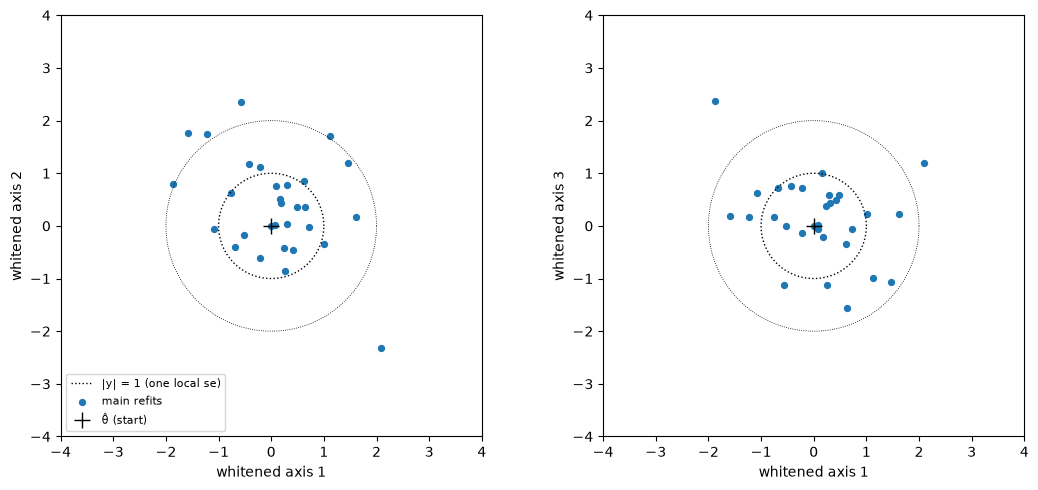

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
t = np.linspace(0, 2 * np.pi, 200)
for ax, (i, j) in zip(axes, ((0, 1), (0, 2))):
    ax.plot(np.cos(t), np.sin(t), "k:", lw=1, label="|y| = 1 (one local se)")
    ax.plot(2 * np.cos(t), 2 * np.sin(t), "k:", lw=0.6)
    ax.scatter(Y[:, i], Y[:, j], s=18, label="main refits")
    ax.plot(0, 0, "k+", ms=12, label="θ̂ (start)")
    ax.set(
        xlabel=f"whitened axis {i + 1}",
        ylabel=f"whitened axis {j + 1}",
        aspect="equal",
        xlim=(-4, 4),
        ylim=(-4, 4),
    )
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
print(f"mean |y|² = {np.mean((Y**2).sum(1)):.2f}   (3 if the spread equals notebook 04's se)")
print(
    f"sd of y per whitened axis: {Y.std(0, ddof=1).round(2)}   (1 if the spread equals notebook 04's se)"
)

**How to read this.**
- **The cloud is roughly round and a bit tighter than one se.** The sd per whitened axis is 0.91, 0.94 and
  0.79 (1 would mean "exactly notebook 04's se"). The mean $|\mathbf y|^2$ is 2.41 against 3.
- **11 of the 30 refits lie within 1 se of θ̂** (in 3D). If the spread were exactly notebook 04's se, about 6 would
  (20%). Most of the rest are within 2 se, and the farthest is at 3.3 se.
- **Two refits hardly moved.** One ended exactly at θ̂: its starting point was the best it ever found in 80
  evaluations. Another moved 0.1 se. That is the trap the control is for, and here it is minor (2 of 30).
- **All 35 fits used their full budget of 80 evaluations**: none met the stopping tolerance.

## 2. The control — did the optimiser converge? (pre-registered)

For datasets 1–5 we have two fits: one from θ̂ ($\mathbf y_0 = 0$) and one from $\mathbf y_0 = (2,-2,2)$. The
table shows where each ended (in whitened units), its ℓ, how far the control travelled from its start,
and the distance between the two ends. The criterion is **distance < 0.5** for all five.

In [3]:
print(
    f"{'pair':>4s} {'main end y':>22s} {'ℓ main':>7s} {'control end y':>22s} {'ℓ ctrl':>7s} {'ctrl moved':>10s} {'distance':>9s}"
)
for i in range(5):
    ym, yc = Y[i], Li @ (np.log(ctrl[i].theta) - np.log(THETA_HAT))
    print(
        f"{i:4d} {str(ym.round(2)):>22s} {main[i].loglik:7.2f} {str(yc.round(2)):>22s} {ctrl[i].loglik:7.2f}"
        f" {np.linalg.norm(yc - Y0):10.2f} {np.linalg.norm(yc - ym):9.2f}"
    )
d = [np.linalg.norm(Li @ (np.log(ctrl[i].theta) - LT[i])) for i in range(5)]
print(
    f"\ncontrol criterion (all distances < 0.5): {'MET' if max(d) < 0.5 else 'NOT met — bootstrap flagged optimiser-limited'}"
)

pair             main end y  ℓ main          control end y  ℓ ctrl ctrl moved  distance
   0    [ 0.72 -0.01 -0.06]   35.92    [ 0.57 -0.19  0.66]   35.37       2.67      0.76
   1    [ 0.62  0.86 -0.34]   34.16    [ 0.56  2.18 -0.14]   34.46       4.91      1.33
   2    [ 2.09 -2.31  1.19]   34.90    [ 1.42 -2.4  -0.09]   35.30       2.21      1.45
   3    [-0.43  1.17  0.76]   34.86    [-0.3   1.48  1.03]   35.06       4.28      0.43
   4    [-1.22  1.74  0.17]   35.25    [-0.88  1.94  0.96]   35.46       4.99      0.89

control criterion (all distances < 0.5): NOT met — bootstrap flagged optimiser-limited


**How to read this.**
- **The control does its job:** 4 of the 5 pairs end more than 0.5 se apart (0.76, 1.33, 1.45, 0.89). Only
  pair 3 agrees (0.43). **As pre-registered, the bootstrap is flagged optimiser-limited.**
- **But this is not "stuck at the start".** Each control fit travelled 2.2–5.0 se from its own start,
  towards the main fit. The optimiser *does* move and finds the same neighbourhood from both starts.
- **Neither start systematically wins.** In pair 0 the main fit has the higher ℓ (35.92 vs 35.37); in the
  other four the control is higher, by only 0.2–0.4 units. Two points ~1 se apart with ℓ within half a unit
  of each other: the top of the likelihood is **flat at the scale of one se**, and both ends are "on the
  plateau". §3 shows why.

## 3. What the control reveals: the top of ℓ is flat *and* rough

**Two numbers to compare at the scale that matters here, one standard error:**
- **The signal.** Moving 1 se away from the maximum lowers ℓ by about ½ (a unit-curvature parabola). Notebook 03's
  follow-up found the B = 40 likelihood sharper by ~2×, so maybe ~1 unit.
- **The noise.** In notebook 03 §1, ℓ at a fixed θ varied by sd ≈ 1 unit between random-number seeds. Even with a
  *fixed* seed, a chaotic simulator makes ℓ jagged at small scales: nearby θ give quite different
  trajectories.

So near the top, signal ≈ noise, and the optimiser cannot locate the maximum better than about one se.
The progress of three main fits (best ℓ found so far) makes it visible:

In [4]:
for i in range(3):
    ll = np.array([p[1] for p in main[i].path])
    run = np.maximum.accumulate(ll)
    print(
        f"fit {i}: best ℓ after 20 / 40 / 60 / 80 evaluations: {run[19]:.2f}  {run[39]:.2f}  {run[59]:.2f}  {run[-1]:.2f}"
    )
print()
print(
    "ℓ spread among the last 20 evaluations of each main fit (sd):",
    np.round([np.std([p[1] for p in f.path[-20:]]) for f in main[:5]], 2),
)

fit 0: best ℓ after 20 / 40 / 60 / 80 evaluations: 35.05  35.44  35.59  35.92
fit 1: best ℓ after 20 / 40 / 60 / 80 evaluations: 34.01  34.16  34.16  34.16
fit 2: best ℓ after 20 / 40 / 60 / 80 evaluations: 34.08  34.16  34.90  34.90

ℓ spread among the last 20 evaluations of each main fit (sd): [0.39 0.87 0.56 0.57 0.49]


**How to read this.**
- **The best ℓ found so far creeps up in small, irregular jumps:** fit 0 goes 35.05 → 35.44 → 35.59 → 35.92,
  fit 1 is stuck at 34.16 from evaluation 40, and fit 2 jumps from 34.16 to 34.90 at evaluation ~60. A smooth
  hilltop would give a steady approach; these are jumps between nearly equal values.
- **Over the last 20 evaluations of each fit, ℓ still varies with sd 0.4–0.9**, while the simplex is only a
  fraction of an se across. That is the size of the small-scale roughness: about the same as the *signal* of
  moving 1 se (≈ ½–1 unit).
- **This revisits notebook 03's Q1.** There, noise was irrelevant (NSR ≤ 0.03), because the signal was measured for a
  **10%** change (40–7400 units). At the scale of the **uncertainty** (1–2%), noise and signal are the same
  size. *"Is the objective noisy?" depends on the precision you ask of it.*

## 4. The bootstrap numbers — read with the flag in mind

These are the pre-registered outputs. Because of §2, they measure the spread of *this estimator with this
optimiser*: the data's variability **plus** the optimiser's ~1 se jitter. They are not a clean statistical
uncertainty.

        bootstrap sd    04 se   ratio   criterion 1/1.5–1.5
η             0.0148   0.0164    0.91   ok
r             0.0165   0.0231    0.72   ok
v₀            0.0048   0.0055    0.87   ok

correlations      bootstrap   04 (Fisher)
  η–r          +0.62       +0.76
  η–v₀         +0.99       +0.99
  r–v₀         +0.55       +0.74

skewness of log r̂_b: +0.40   (0 for a symmetric distribution; with 30 values its se is ≈ 0.43)

80% basic bootstrap intervals (natural scale)       θ* inside?
  η  : [1.9661, 2.0398]   θ̂ = 2.0035   θ* = 2.0000   yes
  r  : [0.9878, 1.0279]   θ̂ = 1.0141   θ* = 1.0000   yes
  v₀ : [0.0298, 0.0302]   θ̂ = 0.0300   θ* = 0.0300   yes


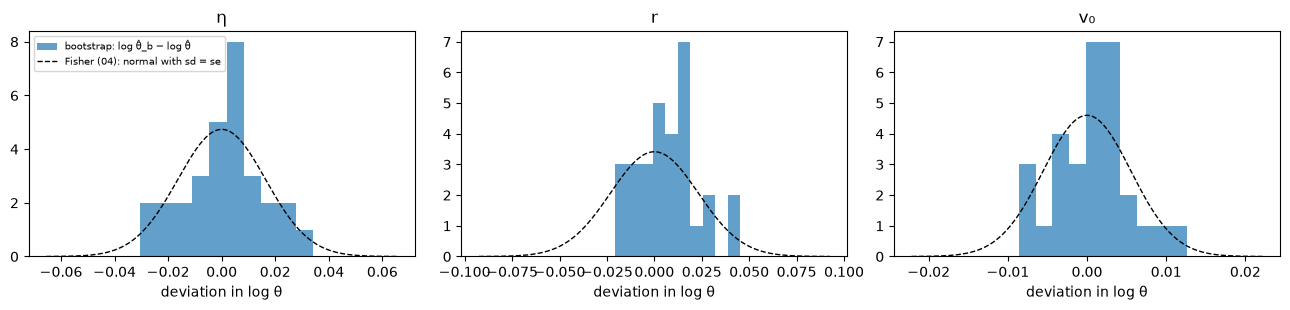

In [5]:
boot_sd = LT.std(0, ddof=1)
print(f"{'':6s} {'bootstrap sd':>13s} {'04 se':>8s} {'ratio':>7s}   criterion 1/1.5–1.5")
for q in range(3):
    print(
        f"{NAMES[q]:6s} {boot_sd[q]:13.4f} {SE[q]:8.4f} {boot_sd[q] / SE[q]:7.2f}   {'ok' if 1 / 1.5 <= boot_sd[q] / SE[q] <= 1.5 else 'OUT'}"
    )
R = np.corrcoef(LT, rowvar=False)
Rf = C / np.outer(SE, SE)
print("\ncorrelations      bootstrap   04 (Fisher)")
for p, q in ((0, 1), (0, 2), (1, 2)):
    print(f"  {NAMES[p]}–{NAMES[q]:3s}        {R[p, q]:+.2f}       {Rf[p, q]:+.2f}")
print(
    f"\nskewness of log r̂_b: {skew(LT[:, 1]):+.2f}   (0 for a symmetric distribution; with 30 values its se is ≈ 0.43)"
)
lo, hi = (
    2 * np.log(THETA_HAT) - np.quantile(LT, 0.9, axis=0),
    2 * np.log(THETA_HAT) - np.quantile(LT, 0.1, axis=0),
)
print("\n80% basic bootstrap intervals (natural scale)       θ* inside?")
for q in range(3):
    print(
        f"  {NAMES[q]:3s}: [{np.exp(lo[q]):.4f}, {np.exp(hi[q]):.4f}]   θ̂ = {THETA_HAT[q]:.4f}   θ* = {TRUTH[q]:.4f}   {'yes' if np.exp(lo[q]) <= TRUTH[q] <= np.exp(hi[q]) else 'NO'}"
    )

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for q, ax in enumerate(axes):
    dev = LT[:, q] - np.log(THETA_HAT[q])
    counts, edges, _ = ax.hist(dev, bins=10, alpha=0.7, label="bootstrap: log θ̂_b − log θ̂")
    xs = np.linspace(-4 * SE[q], 4 * SE[q], 200)
    width = edges[1] - edges[0]  # scale the normal density to expected counts per bin
    ax.plot(
        xs,
        len(dev) * width * np.exp(-0.5 * (xs / SE[q]) ** 2) / (SE[q] * np.sqrt(2 * np.pi)),
        "k--",
        lw=1,
        label="Fisher (04): normal with sd = se",
    )
    ax.set(title=NAMES[q], xlabel="deviation in log θ")
axes[0].legend(fontsize=7)
plt.tight_layout()

**How to read this.** All with the §2 flag in mind: these numbers include roughly 1 se of optimiser jitter per refit.
- **Bootstrap sd / notebook 04 se = 0.91 (η), 0.72 (r), 0.87 (v₀).** All within the pre-registered 1/1.5–1.5, so notebook 04's se
  has the right size. r is where they differ most: notebook 04's local se for r may be ~30% pessimistic.
- **The correlations are similar.** η–v₀ is +0.99 in both: the curved valley of notebook 03 is also the main shape of
  the uncertainty. η–r and r–v₀ are a bit weaker in the bootstrap (+0.62, +0.55 against +0.76, +0.74).
- **Skewness of log r̂: +0.40**, with a standard error of ~0.43 for 30 values, so it is not significant. The
  r histogram does have a longer right tail (up to +0.045), which fits notebook 04's asymmetric profile, but 30 refits
  cannot confirm it.
- **80% intervals:** η [1.966, 2.040] (±1.8%), r [0.988, 1.028] (±2%), v₀ [0.0298, 0.0302] (±0.7%). **θ* lies
  inside all three.** That is one check, not a coverage study: an 80% interval misses the truth one time in
  five by design.
- **Histograms:** the bootstrap distributions are roughly as wide as notebook 04's normal curve for η and v₀, and
  narrower and lumpier for r.

## 5. What this taught us

**The pre-registered verdict: flagged.** 4 of 5 control pairs disagree by more than 0.5 se, so these bootstrap
numbers measure the estimator *including its optimiser's jitter*. They are not clean error bars.

**Why — the main lesson of notebook 05.** The synthetic likelihood is **smooth at the scale of the fit and rough at the
scale of the uncertainty.**
- A 10% change moves ℓ by 40–7400 units, and noise (~1 unit) is irrelevant (notebook 03, Q1).
- A 1-se change (1–2%) moves ℓ by ~½–1 unit, the same as the small-scale roughness a chaotic simulator
  leaves even with fixed random numbers.
- So *maximising* ℓ per dataset cannot pin the maximum better than ~1 se. Any procedure built on repeated
  maximisation (bootstrap, profiles, notebook 04's Q3) inherits that jitter.
- Procedures that **average over** ℓ (a posterior, notebook 06) or **smooth** it before maximising do not.

**What the numbers still say, reading them as an order of magnitude:**
- Notebook 04's local se has the right size. The bootstrap gives 0.7–0.9× it, with the largest gap for r.
- The same correlation structure: η–v₀ ≈ +0.99, the speed valley.
- θ* is inside the 80% intervals, with η ±1.8%, r ±2% and v₀ ±0.7%.
- No evidence of strong start bias: the controls travelled 2–5 se, and only 2 of 30 refits stayed at θ̂.

**Stopping criterion.** If error bars good to about ±30% are enough, **stop here and use notebook 04's Fisher se**; the
bootstrap confirms its order of magnitude. For sharper intervals, the optimiser jitter must go.

**A second attempt (fixed in advance; costs no new simulation).**
- Every ℓ evaluation used seed-0 simulations whose summaries are **stored and do not depend on the data**. So
  for each bootstrap dataset, ℓ can be recomputed at all the ~2500 θ points already simulated near θ̂ for free.
- Fitting a smooth quadratic surface to them (10 coefficients, least squares over the points within ~3 se)
  and taking its maximum removes the roughness and the optimiser altogether. This is a response-surface
  bootstrap.
- The logic is the same as the second attempt of notebook 03: a cheap regression rescues an expensive optimisation.

**Cost.** 35 refits × 80 evaluations took ~1.8 h on 6 processes. Here they are loaded from `results/`.

## 6. A second attempt — smooth the likelihood, then maximise (fixed before running)

**The idea.** In the first part of notebook 05, each refit chased a rough surface. But the rough part is the same for
every dataset, since it comes from the simulations. And the simulations at a given θ **do not depend on the
data**: with seed 0 and 40 runs, $\hat\mu(\theta)$, $\hat\Sigma(\theta)$ and $\log\det\hat\Sigma(\theta)$ are
the same whichever dataset we fit. So we can:
1. take every θ point the 35 fits of §1 already evaluated (2580 unique points, stored in `results/`);
2. for *each* dataset $b$, compute $\ell_b(\theta)$ at all of them at no simulation cost;
3. fit a **smooth quadratic surface** in whitened coordinates to those values and take *its* maximum.

This is a response-surface estimator. It averages over the roughness instead of chasing it.

$$\ell_b(\mathbf y) \approx c_b + \mathbf g_b^\top\mathbf y - \tfrac12\,\mathbf y^\top H_b\,\mathbf y,
\qquad \mathbf y^*_b = H_b^{-1}\mathbf g_b \quad (\text{if } H_b \text{ is positive definite})$$

- **Fit region:** 10 coefficients, least squares over the points with $|\mathbf y| \le 3$ (2380 points).
- **Controls (pre-registered):**
  - *split-half*: fit on two random halves of the points; the maxima must agree within 0.3 se;
  - *region*: $|\mathbf y| \le 2.5$ vs $\le 3.5$; the maxima must agree within 0.3 se.
  - If either fails for more than 3 of the 30 datasets, the second attempt is flagged.
- **Curvature check:** in whitened units, $H \approx I$ would mean the B = 40 likelihood has notebook 04's curvature;
  $H \approx 2I$ would confirm the ~2× sharpening found in notebook 03's follow-up.

In [6]:
from flockladder.synlik import quadratic_max, synlik_from_terms

pts = A["points"]  # np.unique(np.array([p[0] for f in fits for p in f.path]), axis=0)
# gaussian_terms(t) at each point: the mean, precision and log-determinant of its 40 seed-0 runs
terms = list(zip(A["terms_mu"], A["terms_prec"], A["terms_logdet"], strict=True))
s_obs = A["s_obs"]
ELL = np.array(
    [synlik_from_terms(tm, np.vstack([data, s_obs[None]])) for tm in terms]
)  # (points, 31)
YP = (np.log(pts) - np.log(THETA_HAT)) @ Li.T
rad = np.linalg.norm(YP, axis=1)
print(
    f"{len(pts)} unique design points; within |y| ≤ 2.5 / 3 / 3.5: {(rad <= 2.5).sum()} / {(rad <= 3).sum()} / {(rad <= 3.5).sum()}"
)


def est(mask, b):
    return quadratic_max(YP[mask], ELL[mask, b])


fitsRS = [est(rad <= 3, b) for b in range(31)]
bad = [b for b in range(30) if fitsRS[b][0] is None]
print(f"\nno maximum (H not positive definite): {len(bad)} datasets {bad}")
for b in bad:
    print(f"   dataset {b}: eigenvalues of H = {np.linalg.eigvalsh(fitsRS[b][1]).round(2)}")


def dist(a, c):
    return np.nan if a is None or c is None else float(np.linalg.norm(a - c))


half = np.random.default_rng(7).random(len(pts)) < 0.5
split = np.array(
    [dist(est((rad <= 3) & half, b)[0], est((rad <= 3) & ~half, b)[0]) for b in range(30)]
)
region = np.array([dist(est(rad <= 2.5, b)[0], est(rad <= 3.5, b)[0]) for b in range(30)])
for name, dd in (("split-half", split), ("region", region)):
    ok = dd[~np.isnan(dd)]
    print(
        f"{name:10s}: failed (> 0.3 se) in {(ok > 0.3).sum()} of {len(ok)} computable datasets; median {np.median(ok):.2f}, max {ok.max():.1f}"
        f"  -> {'OK' if (ok > 0.3).sum() + np.isnan(dd).sum() <= 3 else 'FLAGGED'}"
    )
sds = [f[2] for f in fitsRS[:30]]
good = [b for b in range(30) if fitsRS[b][0] is not None]
Hm = np.mean([fitsRS[b][1] for b in good], axis=0)
print(
    f"\nresidual sd of the quadratic fits: median {np.median(sds):.2f} (range {min(sds):.2f}–{max(sds):.2f})"
)
print(
    f"mean fitted H (whitened), eigenvalues: {np.linalg.eigvalsh(Hm).round(2)}   (1 = notebook 04's curvature)"
)

2580 unique design points; within |y| ≤ 2.5 / 3 / 3.5: 2217 / 2380 / 2531

no maximum (H not positive definite): 4 datasets [1, 2, 21, 27]
   dataset 1: eigenvalues of H = [-0.14  1.22  1.62]
   dataset 2: eigenvalues of H = [-0.55  1.11  1.83]
   dataset 21: eigenvalues of H = [-1.82  1.29  1.79]
   dataset 27: eigenvalues of H = [-0.94  1.34  1.65]
split-half: failed (> 0.3 se) in 9 of 25 computable datasets; median 0.26, max 25.4  -> FLAGGED
region    : failed (> 0.3 se) in 10 of 26 computable datasets; median 0.29, max 478.8  -> FLAGGED

residual sd of the quadratic fits: median 1.42 (range 0.69–3.38)
mean fitted H (whitened), eigenvalues: [0.93 1.39 2.05]   (1 = notebook 04's curvature)


**How to read this.**
- **The design:** 2580 points, of which 2380 are within 3 se of θ̂. That sounds like plenty, but they are
  *optimiser paths*. They are dense where each fit converged and sparse elsewhere: a poor, uneven design.
- **No maximum for 4 of 30 datasets.** One eigenvalue of the fitted H is negative, so the quadratic is a
  saddle, not a hill.
- **Both controls fail**, so the second attempt is **flagged**:
  - split-half: 9 of 25 computable datasets disagree by more than 0.3 se, with a median of 0.26 but a
    maximum of 25 se;
  - region: 10 of 26 disagree, with a maximum of 479 se.
  - For about two thirds of the datasets the smoothed maximum is stable. For the rest it swings wildly with
    the choice of points.
- **The quadratic is a poor model of ℓ over ±3 se:** the residual sd is 1.4 units (median), up to 3.4. That is
  more than the roughness it was meant to average out (~0.5–1). Over that range ℓ is not a parabola
  (notebook 04 found it asymmetric).
- **The curvature check is informative in its own right.** The mean fitted H in whitened units has eigenvalues
  0.93, 1.39 and 2.05. The B = 40 likelihood is up to **2× sharper** than notebook 04's Fisher in one direction, as the
  notebook 03 follow-up predicted, and about equal in another.

## 7. The second attempt's numbers — pre-registered, then a labelled exploratory robust version

In [7]:
LTR = np.log(THETA_HAT) + np.array([fitsRS[b][0] for b in good]) @ L.T
print(f"pre-registered (all {len(good)} datasets with a maximum):")
print("  bootstrap sd / 04 se:", (LTR.std(0, ddof=1) / SE).round(2))
print(
    "  |y*| of the estimates, sorted:",
    np.sort(np.linalg.norm([fitsRS[b][0] for b in good], axis=1)).round(1),
)
print("\nEXPLORATORY (not pre-registered): robust sd = 1.4826 × median absolute deviation")
mad = 1.4826 * np.median(np.abs(LTR - np.median(LTR, 0)), 0)
print(
    "  robust sd / 04 se:",
    (mad / SE).round(2),
    "   (first attempt, maximisation: 0.91, 0.72, 0.87)",
)
for b in [good[i] for i in np.argsort(np.linalg.norm([fitsRS[g][0] for g in good], axis=1))[-3:]]:
    yb = fitsRS[b][0]
    print(
        f"  far estimate, dataset {b}: y* = {yb.round(1)}; design points within 1 se of it: {(np.linalg.norm(YP - yb, axis=1) <= 1).sum()}"
    )

pre-registered (all 26 datasets with a maximum):
  bootstrap sd / 04 se: [13.94 25.18 13.82]
  |y*| of the estimates, sorted: [  0.5   0.5   0.7   0.9   1.    1.    1.    1.    1.    1.    1.    1.1
   1.3   1.4   1.4   1.5   1.6   1.6   1.9   2.    2.2   2.4   2.7   3.4
   4.  135. ]

EXPLORATORY (not pre-registered): robust sd = 1.4826 × median absolute deviation
  robust sd / 04 se: [0.81 0.91 0.8 ]    (first attempt, maximisation: 0.91, 0.72, 0.87)
  far estimate, dataset 19: y* = [-1.4 -3.1  0.3]; design points within 1 se of it: 0
  far estimate, dataset 29: y* = [-1.4  3.5 -1.3]; design points within 1 se of it: 5
  far estimate, dataset 16: y* = [ 70.8 114.3  12.7]; design points within 1 se of it: 0


**How to read this.**
- **The pre-registered sd ratios (14, 25 and 14× notebook 04's se) are meaningless:** one dataset's "maximum" lies 135
  se away. The sorted |y*| list shows that 23 of the 26 are within ~2.7 se, and then 3.4, 4.0 and 135.
- **The far estimates sit where there are no design points:** 0 points within 1 se of datasets 16 and 19.
  The quadratic *extrapolated* its maximum into empty space. That is the textbook behaviour of response surfaces
  fitted on an undesigned point set.
- **Exploratory, labelled as such:** a robust spread (1.4826 × the median absolute deviation, which ignores
  the few wild values) gives **0.81, 0.91 and 0.80 × notebook 04's se**. That is close to notebook 05's maximisation result
  (0.91, 0.72, 0.87).
- Two different methods, each with its own flag, agree that the uncertainty is **about 0.8–0.9 of notebook 04's local se**.

## 8. What the second attempt taught us

**Pre-registered verdict: flagged.** The smoothed estimator has no maximum for 4 of 30 datasets, and both
stability controls fail (9 of 25 and 10 of 26 datasets over 0.3 se).

**What the flags point to — two specific, fixable causes:**
1. **The design points were recycled optimiser paths.** They are dense where the fits went and empty
   elsewhere, so the quadratic extrapolates into empty regions. A proper response surface needs a
   *designed* point set, uniform around each dataset's maximum.
2. **A quadratic over ±3 se is the wrong model** (residual sd ~1.4, larger than the roughness it was meant
   to remove). ℓ is not a parabola at that range; notebook 04 already saw it asymmetric.

Both could be fixed: a designed local grid of ~50–100 points per region, and a fit over ±1.5 se. But each
fix costs new simulations, and we would be building a whole estimation method to get *error bars* that two
flawed methods already agree on.

**What stands, from both attempts together:**
- The uncertainty of θ̂ from one run is **about 0.8–0.9 of notebook 04's local (Fisher) se**:
  - Notebook 05 (maximisation): 0.91 / 0.72 / 0.87;
  - the second attempt (robust, exploratory): 0.81 / 0.91 / 0.80.
- So η is known to ~±1.5%, r to ~±2% and v₀ to ~±0.5% (1 se) from one run of 40 particles.
- The B = 40 synthetic likelihood is up to 2× sharper than the Fisher information in one direction (the Σ̂
  artefact). A *posterior* built from it (notebook 06) would be **too narrow** by up to ~√2 unless Σ̂ is corrected
  (larger B or shrinkage).

**Stopping criterion — applied here.** For error bars good to ±20–30%, use notebook 04's Fisher se ×0.85. Two more
bootstrap variants would buy precision on the error bar, not on θ. **Stop here.**

**Carry forward to notebook 06:**
- a posterior *averages* over ℓ instead of maximising it, so the roughness should matter less;
- correct Σ̂ before trusting its width;
- the η–v₀ valley (+0.99) calls for a reparametrisation or whitened proposals (notebook 04's L is ready for that).